# 01. Обзорный EDA пассажиропотока метро Нью-Йорка

Что смотрим:
1. Общая динамика системы за 2023–2026 и момент введения платы за въезд.
2. Профили по часам и дням недели.
3. Размер станций: насколько они разные.
4. **Типы станций по форме суточного профиля** (кластеризация): «деловые», «спальные» и т.д.
5. Праздники: насколько они меняют спрос.
6. Школьные каникулы: есть ли эффект и в какие часы.
7. **Станции у стадионов**: есть ли всплески, которые не объясняет календарь.

Важно помнить: в данных MTA только **входы** в метро. Поэтому на «спальной» станции пик утром
(люди уезжают на работу), а на «деловой» — вечером (уезжают домой).

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from dataset import load_dataset

# Палитра: категориальные цвета в фиксированном порядке + приглушённые оси
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#9ec5f4", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2,
    "legend.frameon": False,
})
pd.set_option("display.max_rows", 100, "display.max_colwidth", 60)

def thousands(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"{v/1e6:.1f} млн" if abs(v) >= 1e6 else f"{v/1e3:.0f} тыс")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

In [2]:
df = load_dataset(weather=None)
st = pd.read_parquet("../data/processed/stations.parquet")
name = st.set_index("station_complex_id")["station_complex"]

df["date"] = df["transit_timestamp"].dt.normalize()
print(f"{len(df):,} строк, {df['station_complex_id'].nunique()} станций, "
      f"{df['date'].min():%Y-%m-%d} – {df['date'].max():%Y-%m-%d}")
print(f"Память: {df.memory_usage(deep=True).sum() / 1e9:.2f} ГБ")

13,868,192 строк, 424 станций, 2023-01-01 – 2026-09-24
Память: 0.76 ГБ


## 1. Общая динамика системы

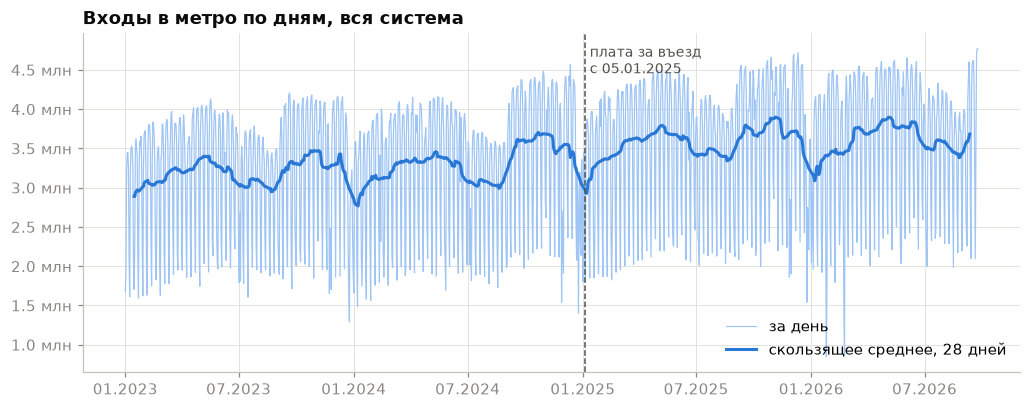

,"средний будний день, январь–сентябрь",к прошлому году
date,,
2023,3610000,
2024,3706000,+2.7%
2025,4031000,+8.8%
2026,4123000,+2.3%


In [3]:
# Суточные суммы по системе + календарные флаги дня
day_cal = (df.drop_duplicates("date")
             .set_index("date")[["dow", "is_holiday", "holiday_name", "is_school_day", "cp_active"]])
system = df.groupby("date")["ridership"].sum().to_frame("ridership").join(day_cal)

fig, ax = plt.subplots()
ax.plot(system.index, system["ridership"], color="#9ec5f4", linewidth=0.8, label="за день")
ax.plot(system.index, system["ridership"].rolling(28, center=True).mean(),
        color=COL[0], label="скользящее среднее, 28 дней")
ax.axvline(pd.Timestamp("2025-01-05"), color=INK2, linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2025-01-12"), ax.get_ylim()[1] * 0.97, "плата за въезд\nс 05.01.2025",
        color=INK2, fontsize=9, va="top")
ax.set_title("Входы в метро по дням, вся система")
thousands(ax)
ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
plt.show()

# Средний будний день по годам (январь–сентябрь, чтобы годы были сопоставимы)
wd = system[(system["dow"] < 5) & (system["is_holiday"] == 0) & (system.index.month <= 9)]
by_year = wd.groupby(wd.index.year)["ridership"].mean()
display(pd.DataFrame({"средний будний день, январь–сентябрь": by_year.round(-3).astype(int),
                      "к прошлому году": by_year.pct_change().map(lambda v: f"{v:+.1%}" if pd.notna(v) else "")}))

## 2. Профили по часам и дням недели

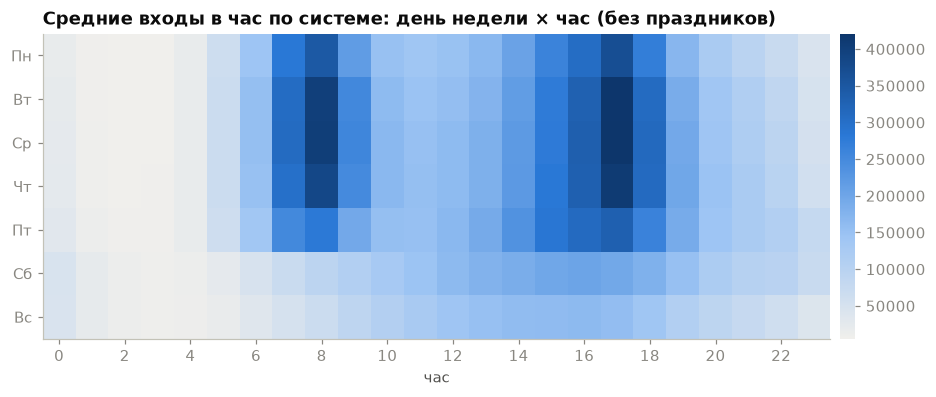

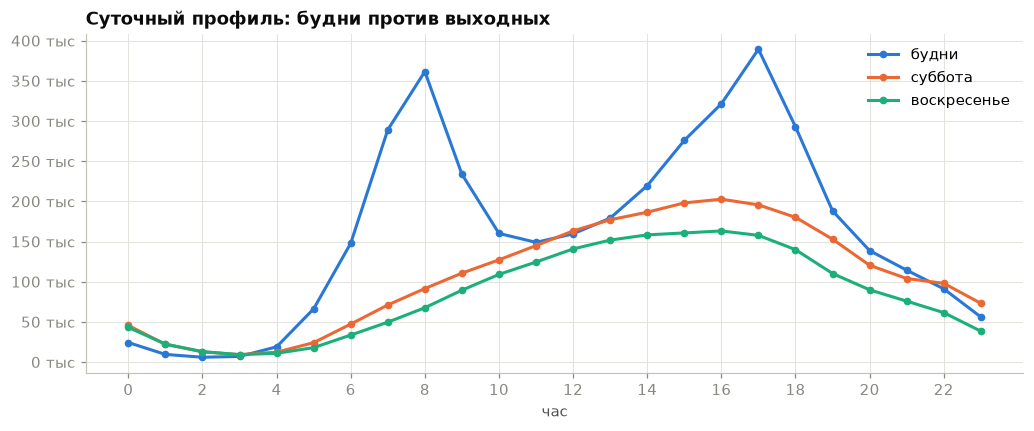

In [4]:
open_ = df[df["is_closed"] == 0]
DOW = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

hourly = open_.groupby(["date", "hour"])["ridership"].sum().reset_index()
hourly = hourly.merge(day_cal[["dow", "is_holiday"]], left_on="date", right_index=True)
hourly = hourly[hourly["is_holiday"] == 0]
heat = hourly.pivot_table(index="dow", columns="hour", values="ridership", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(heat.values, aspect="auto", cmap=BLUES)
ax.set_yticks(range(7), DOW); ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("час"); ax.grid(False)
ax.set_title("Средние входы в час по системе: день недели × час (без праздников)")
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.outline.set_visible(False)
plt.show()

fig, ax = plt.subplots()
for (label, mask), c in zip([("будни", heat.index < 5), ("суббота", heat.index == 5),
                             ("воскресенье", heat.index == 6)], COL):
    prof = heat[mask].mean()
    ax.plot(prof.index, prof.values, color=c, label=label, marker="o", markersize=4)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("час")
ax.set_title("Суточный профиль: будни против выходных"); thousands(ax)
ax.legend(); plt.show()

## 3. Размер станций

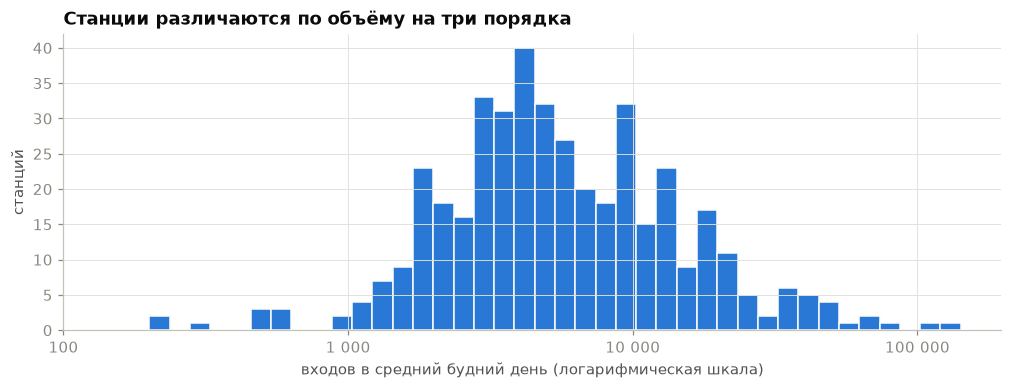

Медиана: 5,078; 10% самых загруженных станций дают 41% всех входов


,станция,входов в будний день
station_complex_id,,
611,"Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,...",141808
610,"Grand Central-42 St (4,5,6,7,S)",113169
607,"34 St-Herald Sq (B,D,F,M,N,Q,R,W)",77909
602,"14 St-Union Sq (4,5,6,L,N,Q,R,W)",70900
628,"Fulton St (2,3,4,5,A,C,J,Z)",63014
164,"34 St-Penn Station (A,C,E)",59685
318,"34 St-Penn Station (1,2,3)",52846
614,"59 St-Columbus Circle (1,A,C,B,D)",52005
447,Flushing-Main St (7),45371


,станция,входов в будний день
station_complex_id,,
202,"Beach 105 St (A,S)",200
199,"Broad Channel (A,S)",208
201,"Beach 98 St (A,S)",311
206,Beach 44 St (A),490
200,"Beach 90 St (A,S)",516


In [5]:
# Средний будний день станции (только открытые дни, без праздников)
sd = (open_[(open_["dow"] < 5) & (open_["is_holiday"] == 0)]
        .groupby(["station_complex_id", "date"], observed=True)["ridership"].sum()
        .groupby("station_complex_id", observed=True).mean().sort_values())
sd.index = sd.index.astype(str)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.hist(np.log10(sd), bins=40, color=COL[0], edgecolor="#fcfcfb", linewidth=1)
ax.set_xticks([2, 3, 4, 5], ["100", "1 000", "10 000", "100 000"])
ax.set_xlabel("входов в средний будний день (логарифмическая шкала)"); ax.set_ylabel("станций")
ax.set_title("Станции различаются по объёму на три порядка")
plt.show()

print(f"Медиана: {sd.median():,.0f}; 10% самых загруженных станций дают "
      f"{sd.nlargest(len(sd)//10).sum() / sd.sum():.0%} всех входов")
top = pd.DataFrame({"станция": name.reindex(sd.index).values, "входов в будний день": sd.round().astype(int).values},
                   index=sd.index)
display(top.tail(10)[::-1]); display(top.head(5))

## 4. Типы станций по форме суточного профиля

Берём для каждой станции средний профиль буднего дня и делим на суточную сумму —
получаем **долю входов в каждый час**. Так большая и маленькая станция с одинаковой «формой» дня
окажутся рядом. Затем кластеризуем профили (KMeans).

In [6]:
wk = open_[(open_["dow"] < 5) & (open_["is_holiday"] == 0)]
prof = (wk.groupby(["station_complex_id", "hour"], observed=True)["ridership"].mean()
          .unstack("hour").fillna(0))
prof.index = prof.index.astype(str)
shares = prof.div(prof.sum(axis=1), axis=0)

# Сколько кластеров: силуэт (чем выше, тем чётче разделение)
for k in range(2, 8):
    lab = KMeans(k, n_init=20, random_state=42).fit_predict(shares)
    print(f"k={k}: silhouette={silhouette_score(shares, lab):.3f}")

k=2: silhouette=0.498
k=3: silhouette=0.358
k=4: silhouette=0.299
k=5: silhouette=0.271
k=6: silhouette=0.280
k=7: silhouette=0.282


,станций,доля входов 6–10 ч,доля входов 16–20 ч,медианный будний день
cluster,,,,
0,95,46%,14%,2900
1,144,39%,20%,4300
2,101,30%,28%,7300
3,84,14%,41%,13600


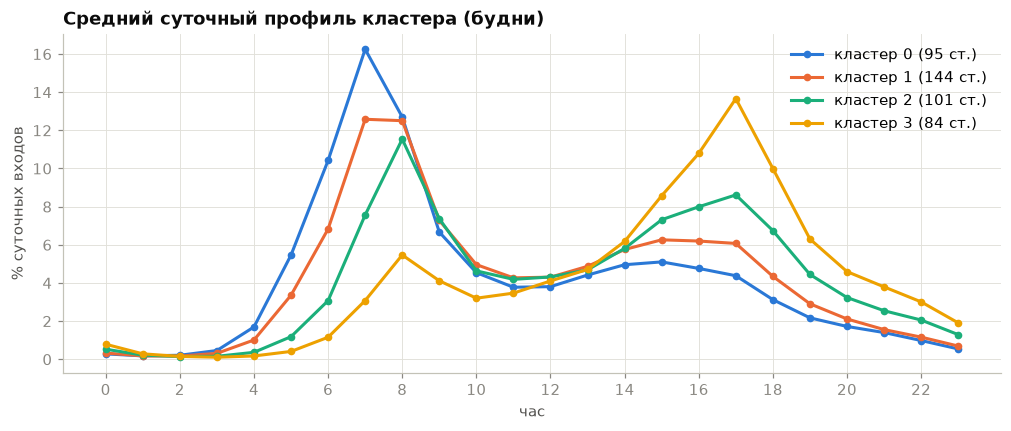

In [7]:
K = 4   # поменяйте, если силуэт выше показывает явно лучшее k
km = KMeans(K, n_init=20, random_state=42).fit(shares)
labels = pd.Series(km.labels_, index=shares.index, name="cluster")

# Упорядочим кластеры по «утренности», чтобы номера были осмысленными и стабильными
morning = shares.loc[:, 6:9].sum(axis=1).groupby(labels).mean()
order = {old: new for new, old in enumerate(morning.sort_values(ascending=False).index)}
labels = labels.map(order)

summary = pd.DataFrame({
    "станций": labels.value_counts().sort_index(),
    "доля входов 6–10 ч": shares.loc[:, 6:9].sum(axis=1).groupby(labels).mean().map("{:.0%}".format),
    "доля входов 16–20 ч": shares.loc[:, 16:19].sum(axis=1).groupby(labels).mean().map("{:.0%}".format),
    "медианный будний день": sd.reindex(labels.index).groupby(labels).median().round(-2).astype(int),
})
display(summary)

fig, ax = plt.subplots()
for c in range(K):
    m = shares[labels == c].mean()
    ax.plot(m.index, m.values * 100, color=COL[c], label=f"кластер {c} ({(labels == c).sum()} ст.)",
            marker="o", markersize=4)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("час"); ax.set_ylabel("% суточных входов")
ax.set_title("Средний суточный профиль кластера (будни)"); ax.legend(); plt.show()

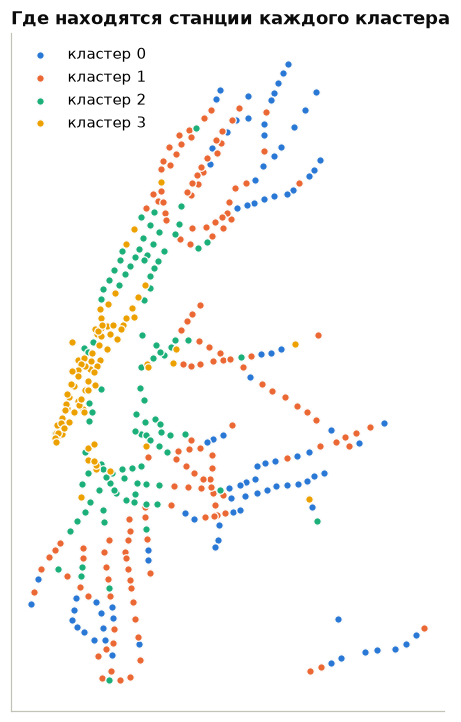

Кластер 0, самые загруженные: Jamaica Center-Parsons/Archer (E,J,Z); Junction Blvd (7); 103 St-Corona Plaza (7); Jamaica-179 St (F); Grand Av-Newtown (M,R); Parkchester (6)
Кластер 1, самые загруженные: Flushing-Main St (7); Jackson Hts-Roosevelt Av/74 St-Broadway (7,E,F,M,R); Sutphin Blvd-Archer Av-JFK Airport (E,J,Z); Forest Hills-71 Av (E,F,M,R); Crown Hts-Utica Av (3,4); Kew Gardens-Union Tpke (E,F)
Кластер 2, самые загруженные: Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,E,N,Q,R,W,S); 34 St-Penn Station (A,C,E); 34 St-Penn Station (1,2,3); Atlantic Av-Barclays Ctr (2,3,4,5,B,D,N,Q,R); 72 St (1,2,3); Bedford Av (L)
Кластер 3, самые загруженные: Grand Central-42 St (4,5,6,7,S); 34 St-Herald Sq (B,D,F,M,N,Q,R,W); 14 St-Union Sq (4,5,6,L,N,Q,R,W); Fulton St (2,3,4,5,A,C,J,Z); 59 St-Columbus Circle (1,A,C,B,D); Chambers St/WTC/Park Place/Cortlandt St (2,3,A,C,E,R,W)


In [8]:
geo = st.set_index("station_complex_id").loc[labels.index]
fig, ax = plt.subplots(figsize=(7, 8))
for c in range(K):
    g = geo[labels == c]
    ax.scatter(g["longitude"], g["latitude"], s=24, color=COL[c], edgecolor="#fcfcfb",
               linewidth=0.8, label=f"кластер {c}")
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.set_title("Где находятся станции каждого кластера"); ax.legend(loc="upper left")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

for c in range(K):
    ids = labels[labels == c].index
    print(f"Кластер {c}, самые загруженные: " + "; ".join(name.reindex(sd.reindex(ids).nlargest(6).index)))

In [9]:
# Сохраняем метки — пригодятся как признак модели и для анализа ошибок
out = pd.DataFrame({"station_complex_id": labels.index, "cluster": labels.values})
out = out.merge(st[["station_complex_id", "station_complex", "borough"]], on="station_complex_id")
out.to_csv("../data/processed/station_clusters.csv", index=False)
print("Сохранено:", len(out), "станций")

Сохранено: 424 станций


## 5. Праздники

Сравниваем каждый праздник с медианой того же дня недели в соседние 3 недели (без праздников).

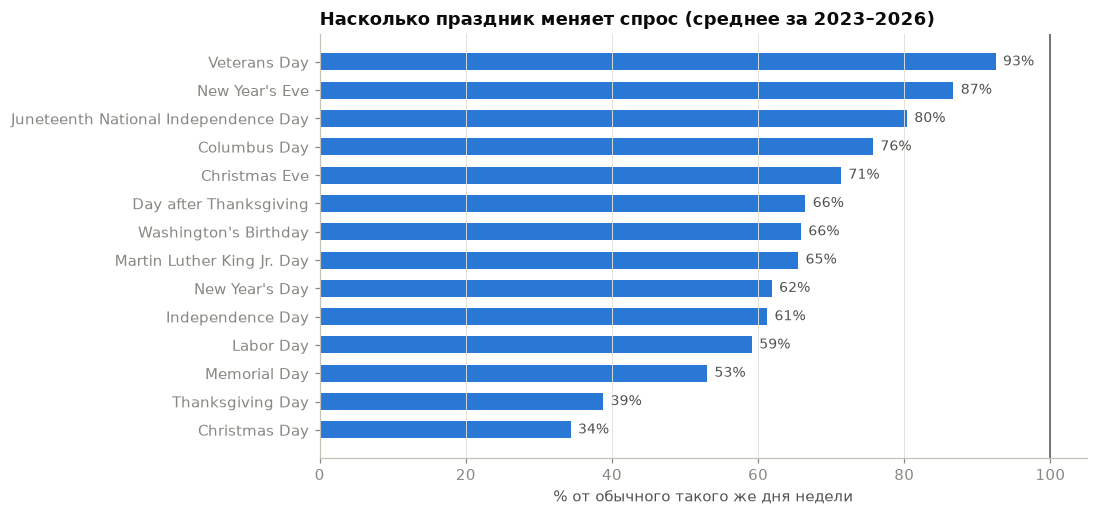

,дата,праздник,день,к обычному дню
28,2024-12-25,Christmas Day,Ср,33%
42,2025-12-25,Christmas Day,Чт,34%
25,2024-11-28,Thanksgiving Day,Чт,36%
14,2023-12-25,Christmas Day,Пн,37%
11,2023-11-23,Thanksgiving Day,Чт,40%
39,2025-11-27,Thanksgiving Day,Чт,41%
30,2025-01-01,New Year's Day,Ср,45%
19,2024-05-27,Memorial Day,Пн,46%
6,2023-07-04,Independence Day,Вт,49%
44,2026-01-01,New Year's Day,Чт,49%


In [10]:
base = system[system["is_holiday"] == 0]
rows = []
for d, r in system[system["is_holiday"] == 1].iterrows():
    near = base[(base["dow"] == r["dow"]) & (abs((base.index - d).days) <= 21)]
    rows.append({"дата": d.date(), "праздник": str(r["holiday_name"]).replace(" (observed)", ""), "день": DOW[r["dow"]],
                 "к обычному дню": r["ridership"] / near["ridership"].median()})
hol = pd.DataFrame(rows)
hol_avg = hol.groupby("праздник")["к обычному дню"].mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(hol_avg.index, hol_avg.values * 100, color=COL[0], height=0.6)
ax.axvline(100, color=INK2, linewidth=1)
for y, v in enumerate(hol_avg.values):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color=INK2)
ax.set_xlabel("% от обычного такого же дня недели")
ax.set_title("Насколько праздник меняет спрос (среднее за 2023–2026)")
ax.grid(axis="y", visible=False); plt.show()
display(hol.sort_values("к обычному дню").assign(**{"к обычному дню": lambda t: t["к обычному дню"].map("{:.0%}".format)}))

## 6. Школьные каникулы

Каникулы во время учебного года (зимние, весенние, отдельные дни) сравниваем с учебными днями
того же дня недели в соседние 3 недели. Летние каникулы не берём: там смешивается сезонный эффект.

Будних дней каникул внутри учебного года: 77


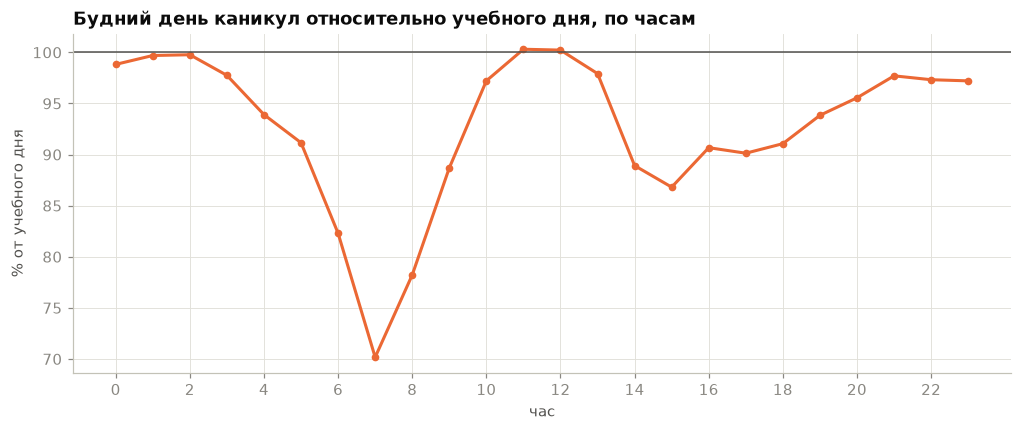

За сутки в целом: 89% (грубое сравнение, без поправки на сезон)


In [11]:
wh = hourly.merge(day_cal[["is_school_day"]], left_on="date", right_index=True)
wh = wh[wh["dow"] < 5]
P = wh.pivot_table(index="date", columns="hour", values="ridership")
school = day_cal[day_cal["is_school_day"] == 1].index

# «внутри учебного года»: учебный день есть и в 10 днях до, и в 10 днях после
def in_school_year(d):
    return ((school < d) & (school >= d - pd.Timedelta(days=10))).any() and \
           ((school > d) & (school <= d + pd.Timedelta(days=10))).any()

recess = [d for d in P.index if day_cal.loc[d, "is_school_day"] == 0 and in_school_year(d)]
ratios = []
for d in recess:
    near = [x for x in school if abs((x - d).days) <= 21 and x.dayofweek == d.dayofweek and x in P.index]
    if near:
        ratios.append(P.loc[d] / P.loc[near].mean())
ratio = pd.concat(ratios, axis=1).mean(axis=1)
print(f"Будних дней каникул внутри учебного года: {len(ratios)}")

fig, ax = plt.subplots()
ax.plot(ratio.index, ratio.values * 100, color=COL[1], marker="o", markersize=4)
ax.axhline(100, color=INK2, linewidth=1)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("час"); ax.set_ylabel("% от учебного дня")
ax.set_title("Будний день каникул относительно учебного дня, по часам"); plt.show()
print(f"За сутки в целом: {(P.loc[recess].sum(axis=1).mean() / P.loc[school.intersection(P.index)].sum(axis=1).mean()):.0%} "
      "(грубое сравнение, без поправки на сезон)")

## 7. Станции у стадионов и арен

Для каждой станции считаем **вечерние входы (17–23 ч)** относительно скользящей медианы того же
дня недели за 8 недель. Всплеск = вечер намного выше обычного. Times Sq — контрольная станция без стадиона.

Yankee Stadium            -> 161 St-Yankee Stadium (4,B,D)
Citi Field / US Open      -> Mets-Willets Point (7)
Barclays Center           -> Atlantic Av-Barclays Ctr (2,3,4,5,B,D,N,Q,R)
Madison Square Garden     -> 34 St-Penn Station (A,C,E)
контроль: Times Sq        -> Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,E,N,Q,R,W,S)


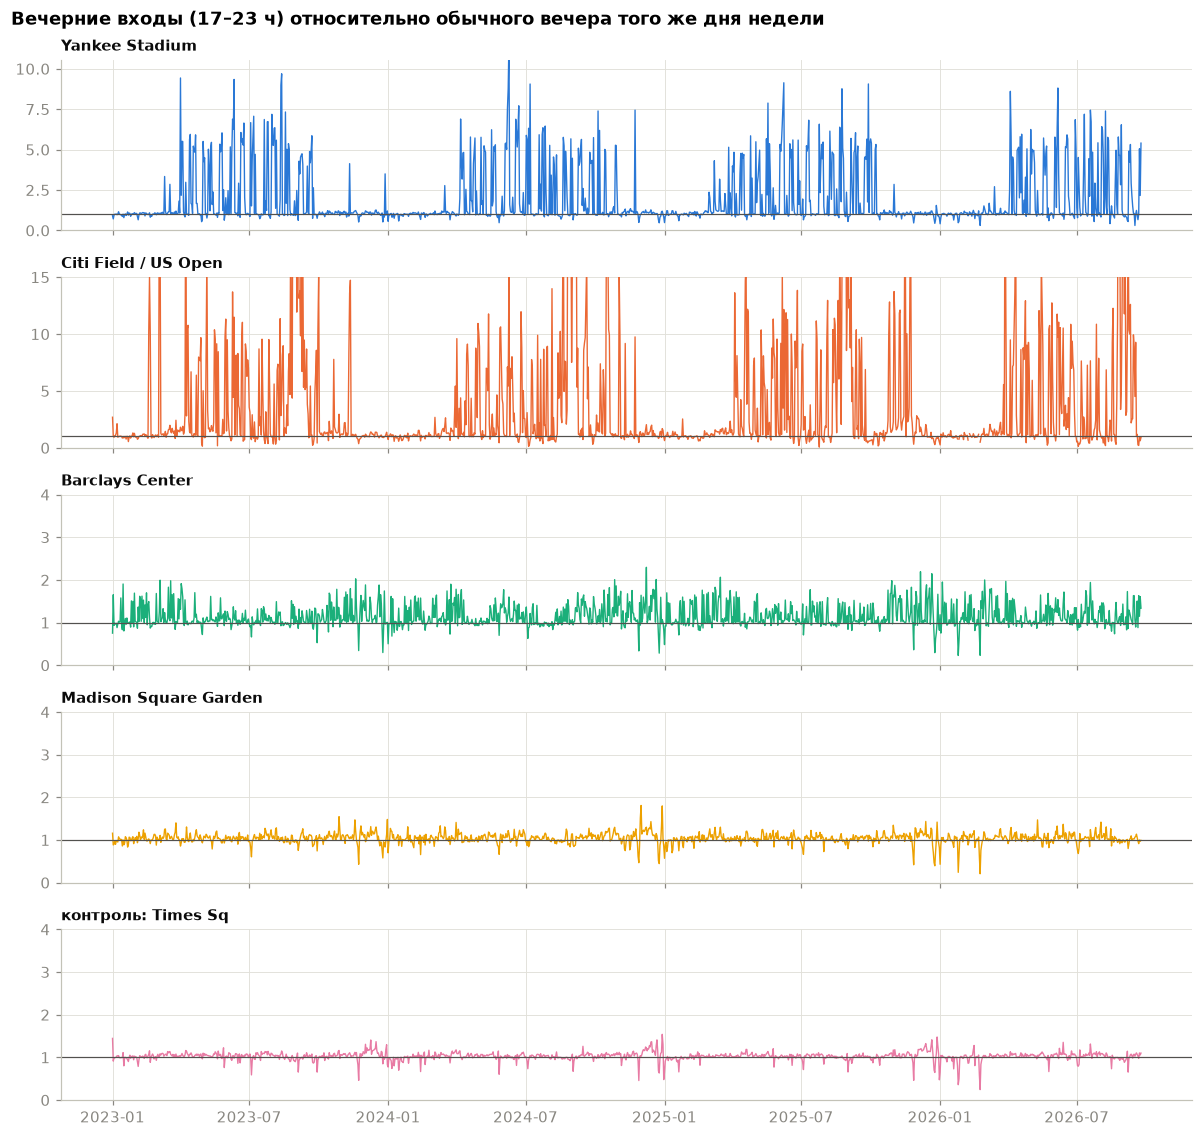

Доля вечеров со всплеском > 1,5x обычного:


,доля вечеров
Yankee Stadium,26.0%
Citi Field / US Open,38.1%
Barclays Center,13.7%
Madison Square Garden,0.3%
контроль: Times Sq,0.1%


In [12]:
VENUES = {
    "Yankee Stadium": "161 St-Yankee Stadium",
    "Citi Field / US Open": "Willets",
    "Barclays Center": "Atlantic Av-Barclays",
    "Madison Square Garden": "34 St-Penn Station (A,C,E)",
    "контроль: Times Sq": "Times Sq",
}
ev = open_[open_["hour"].between(17, 23)]
found = {}
for label, pat in VENUES.items():
    ids = st.loc[st["station_complex"].str.contains(pat, regex=False), "station_complex_id"]
    if len(ids):
        found[label] = ids.iloc[0]
        print(f"{label:25s} -> {name[ids.iloc[0]]}")
    else:
        print(f"{label:25s} -> не найдено, проверьте название в stations.parquet")

anom = {}
for label, sid in found.items():
    s = ev[ev["station_complex_id"] == sid].groupby("date")["ridership"].sum()
    # «обычный вечер» = 30-й перцентиль того же дня недели за ±8 недель:
    # устойчив, даже если матчи идут в половине вечеров сезона
    base_ = s.groupby(s.index.dayofweek).transform(
        lambda x: x.rolling(17, center=True, min_periods=6).quantile(0.3))
    anom[label] = s / base_
anom = pd.DataFrame(anom)

fig, axes = plt.subplots(len(anom.columns), 1, figsize=(11, 2.1 * len(anom.columns)), sharex=True)
for ax, col, c in zip(np.atleast_1d(axes), anom.columns, COL):
    ax.plot(anom.index, anom[col], color=c, linewidth=0.9)
    ax.axhline(1, color=INK2, linewidth=0.8)
    ax.set_ylim(0, max(4, min(anom[col].quantile(0.999) * 1.1, 15)))
    ax.set_title(col, fontsize=10)
fig.suptitle("Вечерние входы (17–23 ч) относительно обычного вечера того же дня недели",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

share_spikes = (anom > 1.5).mean().map("{:.1%}".format)
print("Доля вечеров со всплеском > 1,5x обычного:"); display(share_spikes.to_frame("доля вечеров"))

In [13]:
# Топ-10 всплесков по каждой станции: сверьте с расписанием матчей/концертов
for col in anom.columns:
    t = anom[col].nlargest(10)
    print(f"\n{col}:")
    print("  " + ", ".join(f"{d:%d.%m.%Y} ({DOW[d.dayofweek]}) ×{v:.1f}" for d, v in t.items()))


Yankee Stadium:
  09.06.2024 (Вс) ×11.7, 13.08.2023 (Вс) ×9.7, 01.04.2023 (Сб) ×9.4, 11.06.2023 (Вс) ×9.3, 08.06.2025 (Вс) ×9.1, 28.09.2025 (Вс) ×9.1, 07.07.2024 (Вс) ×9.1, 12.08.2023 (Сб) ×9.0, 06.06.2026 (Сб) ×8.8, 24.08.2025 (Вс) ×8.8

Citi Field / US Open:
  02.09.2024 (Пн) ×36.3, 29.08.2023 (Вт) ×34.8, 25.08.2025 (Пн) ×34.8, 28.08.2023 (Пн) ×33.4, 27.08.2025 (Ср) ×32.2, 25.08.2026 (Вт) ×32.1, 26.08.2025 (Вт) ×31.6, 01.09.2023 (Пт) ×31.0, 30.08.2023 (Ср) ×30.5, 28.08.2025 (Чт) ×30.3

Barclays Center:
  08.12.2024 (Вс) ×2.3, 06.12.2025 (Сб) ×2.2, 21.12.2025 (Вс) ×2.1, 16.03.2025 (Вс) ×2.1, 19.11.2023 (Вс) ×2.0, 21.12.2024 (Сб) ×2.0, 27.10.2024 (Вс) ×2.0, 01.03.2026 (Вс) ×2.0, 05.03.2023 (Вс) ×2.0, 29.10.2025 (Ср) ×2.0

Madison Square Garden:
  01.12.2024 (Вс) ×1.8, 29.12.2024 (Вс) ×1.8, 28.10.2023 (Сб) ×1.5, 30.11.2024 (Сб) ×1.5, 31.12.2023 (Вс) ×1.5, 18.11.2023 (Сб) ×1.5, 10.05.2026 (Вс) ×1.5, 13.12.2025 (Сб) ×1.4, 14.12.2024 (Сб) ×1.4, 28.12.2025 (Вс) ×1.4

контроль: Times Sq:
  

## Что зафиксировать по итогам

Ответьте себе по каждому разделу — это заготовки текста для главы с анализом данных:
1. Как менялся спрос по годам и виден ли скачок после 05.01.2025?
2. Насколько выражены утренний и вечерний пики, чем отличаются выходные?
3. Насколько неравномерна нагрузка между станциями?
4. Сколько типов станций получилось и как их можно назвать? Совпадает ли карта с интуицией
   (центр Манхэттена — «деловые», окраины — «спальные»)?
5. Какие праздники сильнее всего снижают спрос?
6. В какие часы каникулы сильнее всего отличаются от учебного дня?
7. Есть ли у станций со стадионами всплески, которых нет у контрольной станции?
   Если да — это обоснование добавить расписание событий.